Makine Öğrenmesinde Fairness

1. Fairness (Adillik) Nedir?

    - Makine öğrenmesi modellerinin farklı gruplar için adil ve tarafsız kararlar vermesi
    - Hassas özelliklere (cinsiyet, ırk, yaş vb.) dayalı ayrımcılık yapmaması
    - Var olan toplumsal eşitsizlikleri pekiştirmemesi

2. Fairness Türleri:

    a) Grup Adaleti:

        - Farklı grupların benzer oranlarda olumlu/olumsuz sonuç alması
        - Örnek: Kredi başvurularında kadın/erkek onay oranlarının dengeli olması

    b) Bireysel Adalet:

        - Benzer özelliklere sahip bireylerin benzer sonuçlar alması
        - Örnek: Benzer gelir ve kredi geçmişine sahip kişilerin benzer kredi notları alması

    c) Fırsat Eşitliği:

        - Gerçekte hak eden her bireyin eşit şansa sahip olması
        - Örnek: İşe alımlarda tüm nitelikli adayların eşit değerlendirilmesi

3. Ne Zaman Fairness Problemi Vardır?

    Oransal Dengesizlik:
    
        Gruplar arası pozitif sonuç oranları çok farklıysa
        Örnek: Erkeklere kadınlardan 4 kat daha fazla yüksek gelir tahmini

    Performans Farklılıkları:

        Model bazı gruplarda diğerlerinden daha başarılıysa
        Örnek: Yaşlı grupta gençlere göre daha düşük doğruluk oranı

    Sistematik Yanlılık:
    
        Belirli gruplar sürekli dezavantajlı durumdaysa
        Örnek: Azınlık gruplarına sürekli düşük kredi notu verilmesi


Örnek Üzerinden (Gelir Tahmini):

1. Problem Tespiti:

    Kadınlara erkeklerden daha az yüksek gelir tahmini
    Azınlık gruplarında düşük doğruluk oranları
    Yaş grupları arası dengesiz tahminler

Çözüm Yaklaşımları:

    Veri setinde grup dengesi sağlama
    Model eğitiminde grup ağırlıkları kullanma
    Sonuçları grup bazlı kalibre etme

Sonuç Değerlendirme:

    Grup bazlı performans metrikleri
    Fairness metriklerinin takibi
    Düzenli bias analizi

#### Case Nedir?

### Case Nedir?

Tahmin görevi, bir kişinin yıllık gelirinin 50.000 doların üzerinde olup olmadığını belirlemektir.

Toplam Gözlem Sayısı: 48,842

Özellik Sayısı: 15

Sütunlar

1. age: Bireyin yaşı
2. workclass: Çalışma sınıfı (ör. Private, Local-gov, vs.) (Özel Sektör, kendi işi gibi)
3. fnklwgt: Son ağırlık (örnekleme ağırlığını ifade der) (bireyin demografik gruplar arasında temsil ettiği tahmini kişi satısı)
4. education: Eğitim düzeyi (ör. HS-grad, Assoc-acdm, vs.)
5. education-num: Eğitim seviyesi (sayı olarak)
6. marital-status: Medeni durum (ör. Never-married, Married-civ-spouse, vs.).
7. occupation: Meslek (ör. Machine-op-inspct, Farming-fishing, vs.).
8. relationship: Aile içindeki rol (ör. Own-child, Husband, vs.).
9. race: Irk (ör. White, Black, vs.).
10. sex: Cinsiyet (ör. Male, Female).
11. capital-gain: Sermaye kazancı (tam sayı). (bireyin bir yılda sermaye varlıklarını satarak elde ettiği kazanç)
12. capital-loss: Sermaye kaybı (tam sayı). (sermaye varlıklarını satarak uğradığı zarar)
13. hours-per-week: Haftalık çalışma saati.
14. native-country: Doğum ülkesi (ör. United-States)
15. income: Gelir seviyesi (<=50K veya >50K olarak kategorize edilmiş)

In [47]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

In [48]:
print("Veri yükleniyor...")
df = pd.read_csv('../datasets/Census Income/census.csv')

print("Veri seti boyutu:", df.shape)
print("\nDeğişken tipleri:\n", df.dtypes)
print("\nEksik değerler:\n", df.isnull().sum())
print("\nSınıf dağılımı:\n", df['income'].value_counts(normalize=True))

Veri yükleniyor...
Veri seti boyutu: (48842, 15)

Değişken tipleri:
 age                int64
workclass         object
fnlwgt             int64
education         object
education-num      int64
marital-status    object
occupation        object
relationship      object
race              object
sex               object
capital-gain       int64
capital-loss       int64
hours-per-week     int64
native-country    object
income            object
dtype: object

Eksik değerler:
 age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64

Sınıf dağılımı:
 income
<=50K    0.760718
>50K     0.239282
Name: proportion, dtype: float64


workclass için eksik değer sayısı: 2799
occupation için eksik değer sayısı: 2809
native-country için eksik değer sayısı: 857


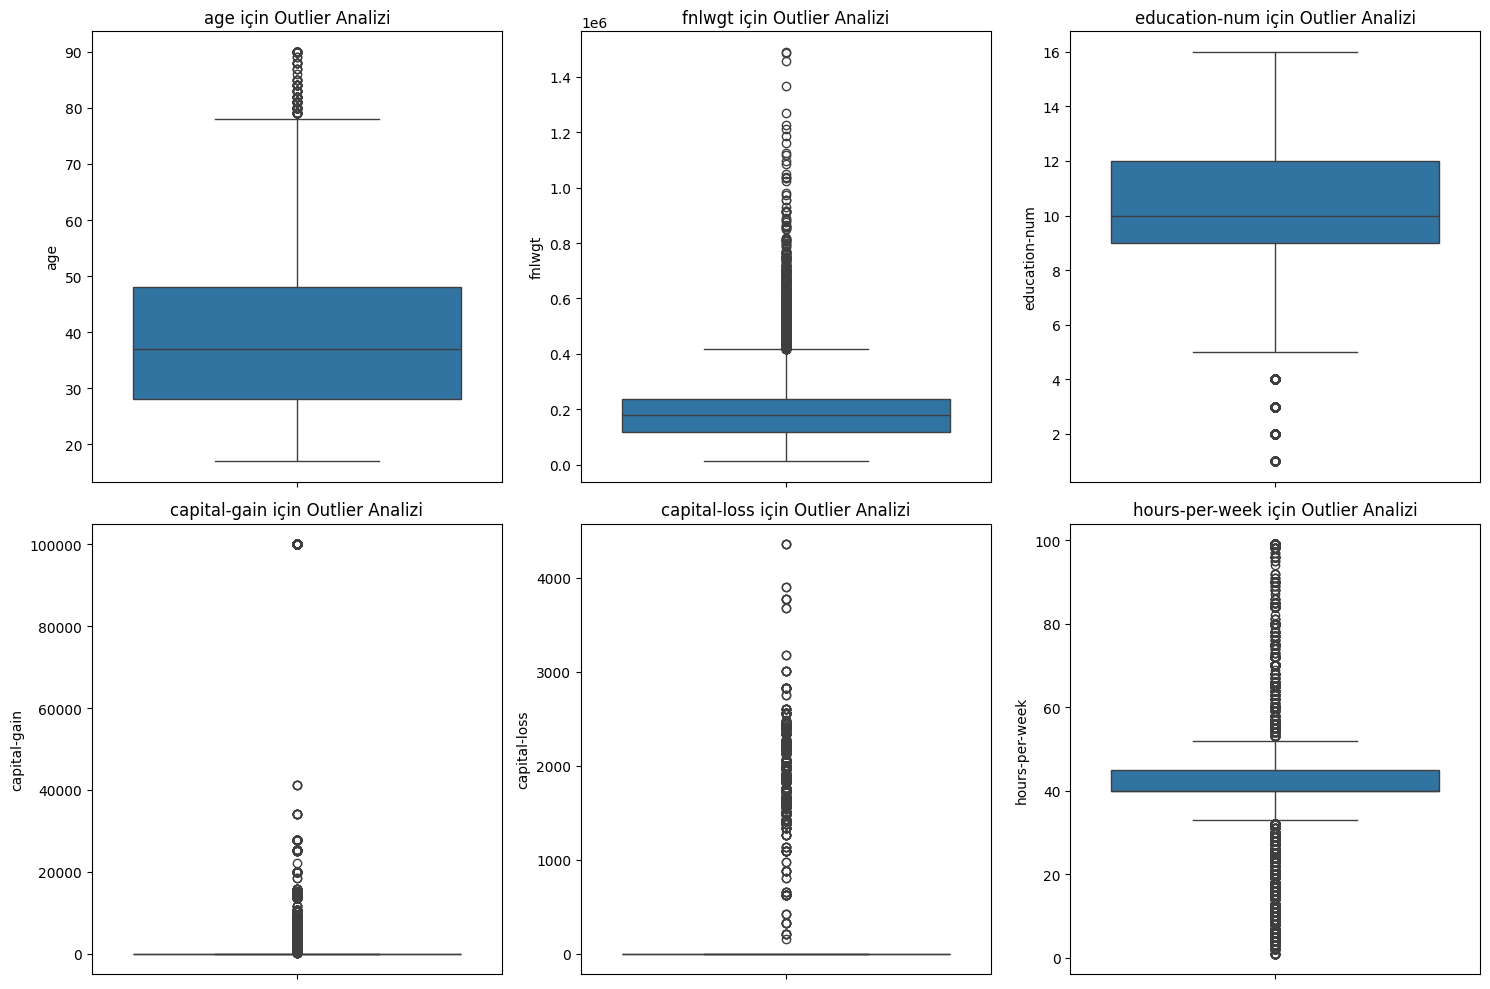


age için:
Outlier sayısı: 216
Outlier yüzdesi: %0.44

fnlwgt için:
Outlier sayısı: 1453
Outlier yüzdesi: %2.97

education-num için:
Outlier sayısı: 1794
Outlier yüzdesi: %3.67

capital-gain için:
Outlier sayısı: 4035
Outlier yüzdesi: %8.26

capital-loss için:
Outlier sayısı: 2282
Outlier yüzdesi: %4.67

hours-per-week için:
Outlier sayısı: 13496
Outlier yüzdesi: %27.63


In [49]:
def preprocess_data(df):
    # Missing Values
    df = df.replace('?', np.nan)

    for col in df.columns:
        if df[col].isnull().any():
            print(f"{col} için eksik değer sayısı: {df[col].isnull().sum()}")
            df[col] = df[col].fillna(df[col].mode()[0])
    
    # Workclass için eksik değerleri doldur
    workclass_mask = df['workclass'].isna()
    if workclass_mask.any():
        df.loc[workclass_mask, 'workclass'] = df[workclass_mask].groupby(['education', 'occupation'])['workclass'].transform(lambda x: x.mode()[0])
    
    # Occupation için eksik değerleri doldur
    occupation_mask = df['occupation'].isna()
    if occupation_mask.any():
        df.loc[occupation_mask, 'occupation'] = df[occupation_mask].groupby(['education', 'education-num'])['occupation'].transform(lambda x: x.mode()[0])
    
    # Native-country için eksik değerleri doldur
    country_mask = df['native-country'].isna()
    if country_mask.any():
        df.loc[country_mask, 'native-country'] = df[country_mask].groupby(['race'])['native-country'].transform(lambda x: x.mode()[0])
    
    # Kalan eksik değerler varsa mode ile doldur
    for col in df.columns:
        if df[col].isnull().any():
            print(f"{col} için kalan eksik değer sayısı: {df[col].isnull().sum()}")
            df[col] = df[col].fillna(df[col].mode()[0])
    
    # Yaş gruplarını oluşturma
    df['age_group'] = pd.qcut(df['age'], q=10, labels=[f'age_group_{i+1}' for i in range(10)])
    
    # Sayısal değişkenler için outlier analizi
    numeric_cols = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
    
    plt.figure(figsize=(15, 10))
    for i, col in enumerate(numeric_cols, 1):
        plt.subplot(2, 3, i)
        sns.boxplot(data=df, y=col)
        plt.title(f'{col} için Outlier Analizi')
    plt.tight_layout()
    plt.show()
    
    # IQR yöntemi ile outlier tespiti ve işleme
    for col in numeric_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
        outlier_percentage = (outliers / len(df)) * 100
        
        print(f"\n{col} için:")
        print(f"Outlier sayısı: {outliers}")
        print(f"Outlier yüzdesi: %{outlier_percentage:.2f}")
        
        # Outlier'ları sınırlama (capping)
        df[col] = df[col].clip(lower=lower_bound, upper=upper_bound)
    
    return df


df = preprocess_data(df)

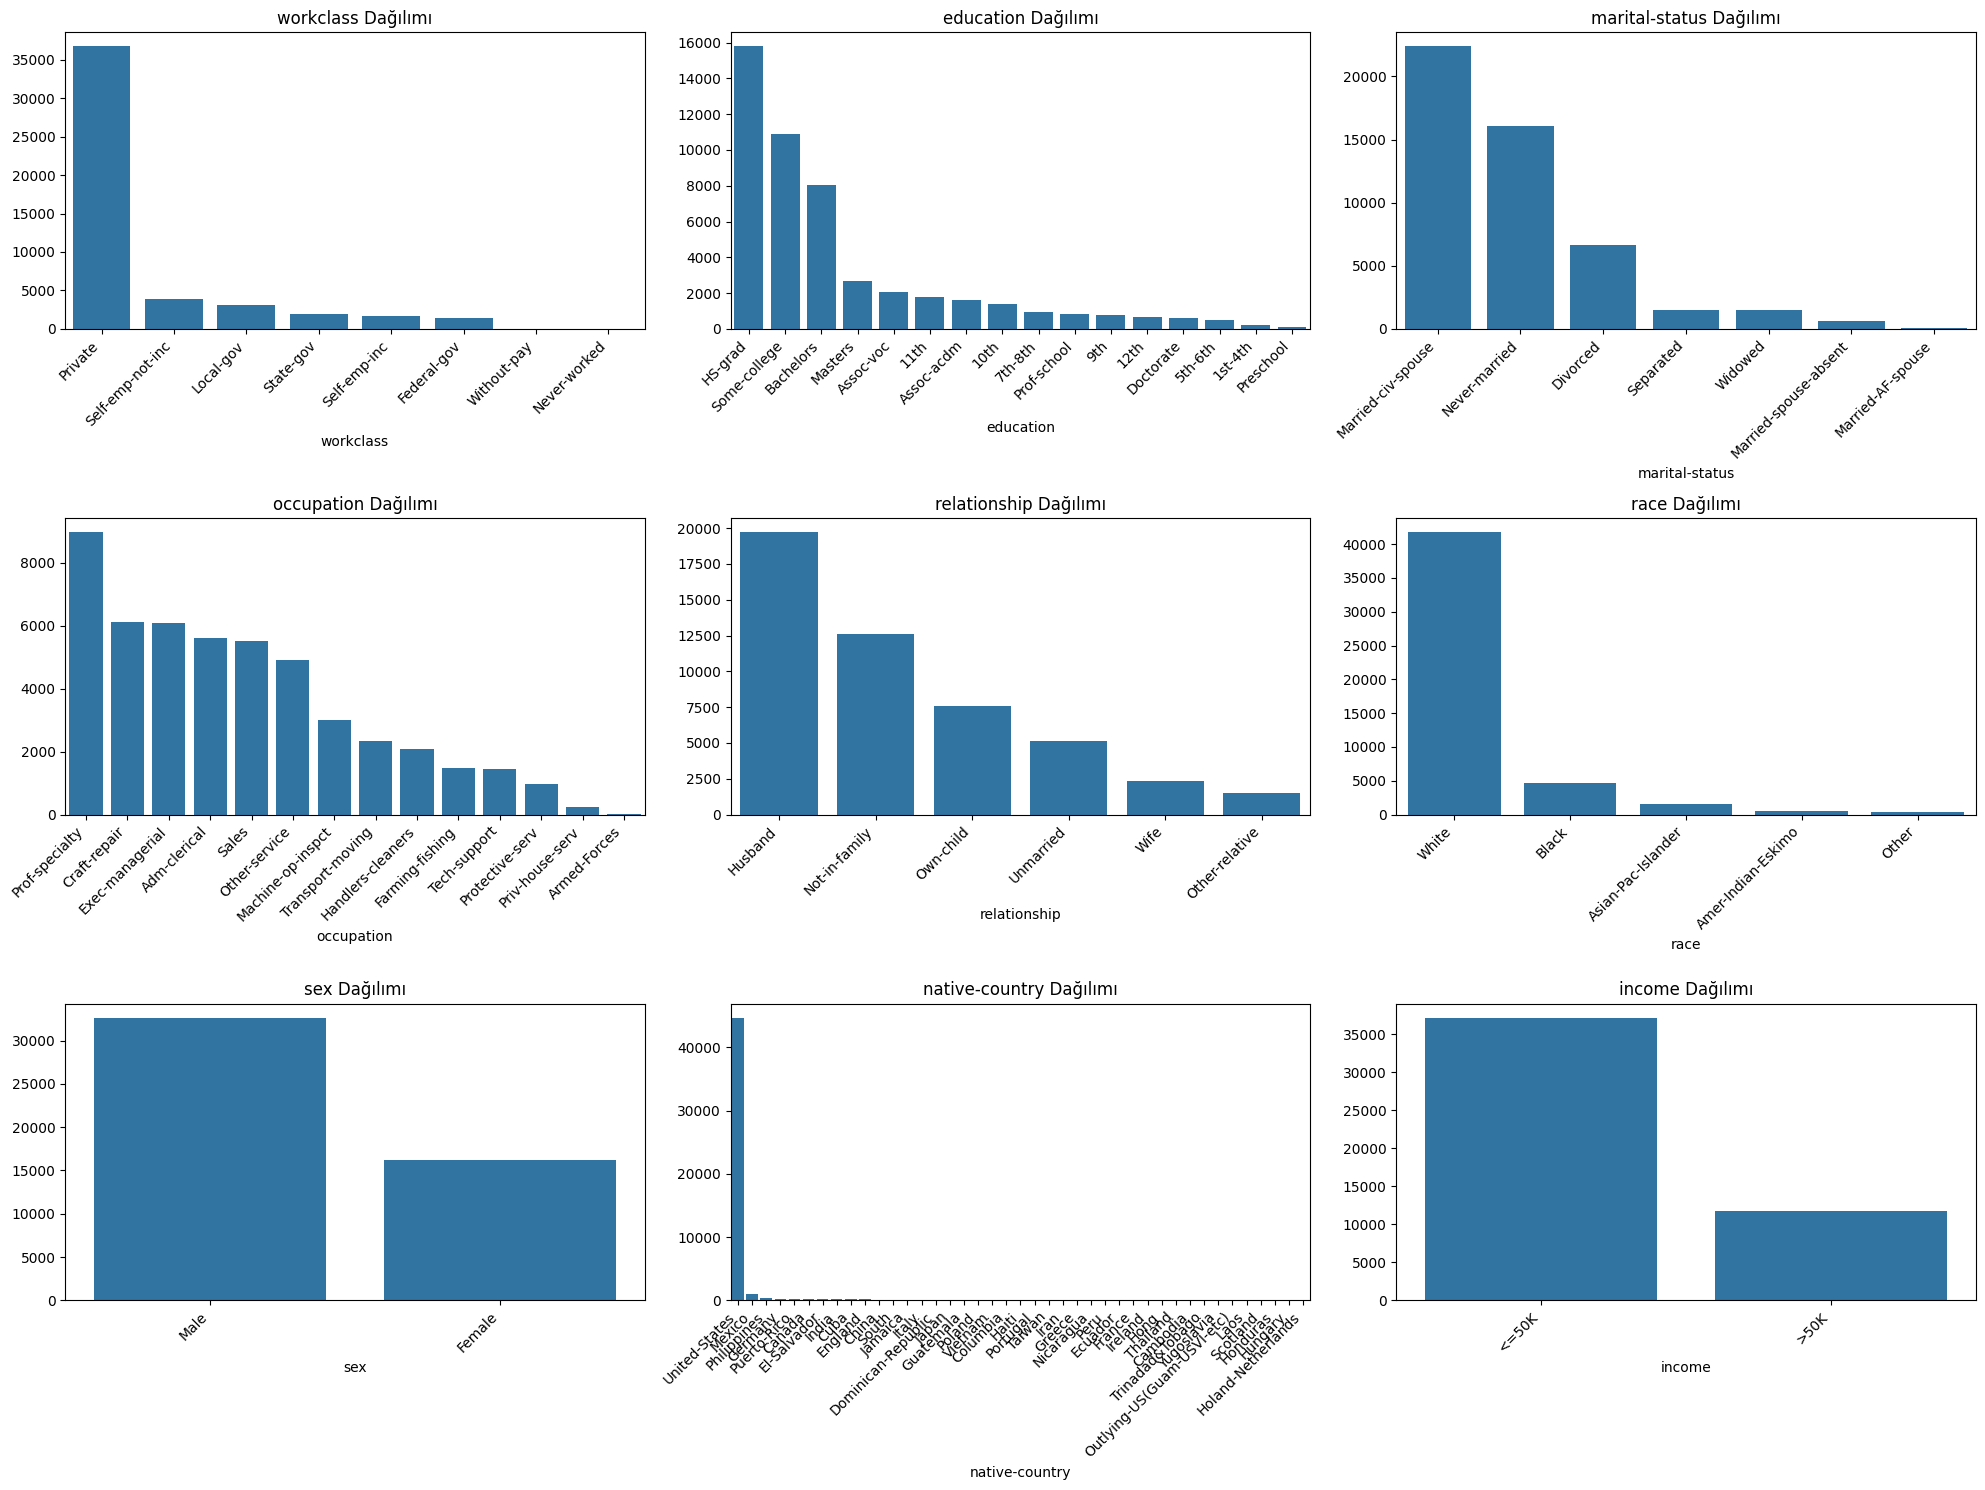

In [50]:
#Kategorik değişkenlerin görselleştirilmesi
plt.figure(figsize=(20, 15))

categorical_cols = df.select_dtypes(include=['object']).columns
n_cols = len(categorical_cols)
n_rows = (n_cols + 2) // 3

for i, col in enumerate(categorical_cols, 1):
    plt.subplot(n_rows, 3, i)
    value_counts = df[col].value_counts()
    sns.barplot(x=value_counts.index, y=value_counts.values)
    plt.title(f'{col} Dağılımı')
    plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()



# Workclass -> Private sektörde çalışanlar açık ara fazla, Ciddi bir dengesizlik var
# Education -> HS-grad (Lise mezunu) en yüksek, Yüksek eğitim seviyelerinde sayılar oldukça düşük
# Marital-status -> Married-civ-spouse ve never married yüksek, Diğer kategoriler ise oldukça düşük
# Occupation -> Prof-speciality, Meslek grupları arasında dengeli bir dağılım var
# Relationship -> Husband en yüksek, own-child ve not-in-family takip ediyor
# Race -> White kategorisi en baskın, Diğer ırkla çok daha az sayıda temsil ediyor, Veri setinde ciddi bir ırk dengesizliği mevcut
# Sex -> Yaklaşık 2:1 oranında erkek ağırlıklı, Cinsiyet dengesizliği mevcut
# Native - Country -> United States, Diğer ülkeler çok az temsil ediliyor
# Income -> <= 50K gelir grubu (~35000),  > 50K gelir grubu (~12000), Gelir gruplarında dengesizlik var

# Genel değerlendirme 
    # Veri setinde birçok kategoride dengesizlikler mevcut
    # Bu dengesizlikler model eğitiminde bias'a neden olabilir
    # Özellikle Cinsiyet, Irk, Gelir, Workclass

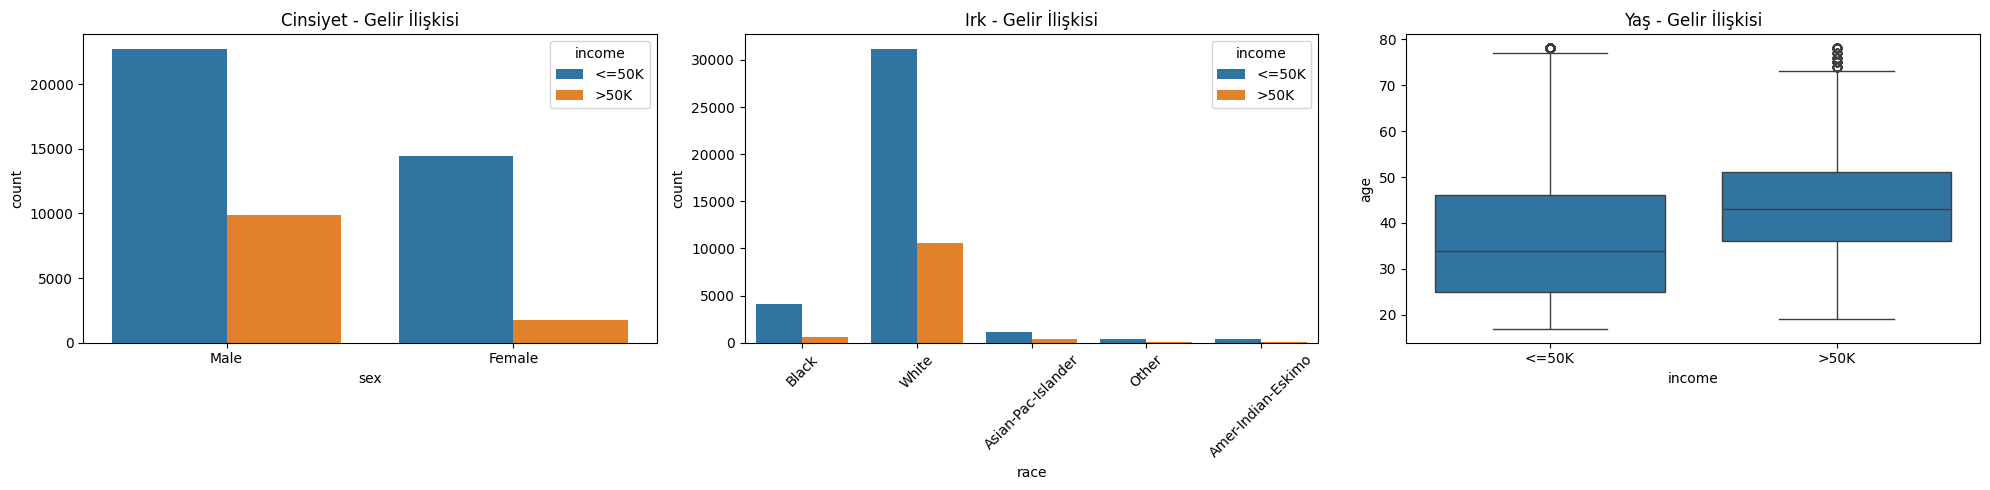

In [51]:
# Hassas değişkenlerin analizi
plt.figure(figsize=(20, 5))

# Cinsiyet - Gelir ilişkisi
plt.subplot(1, 3, 1)
sns.countplot(data=df, x='sex', hue='income')
plt.title('Cinsiyet - Gelir İlişkisi')

# Irk - Gelir ilişkisi
plt.subplot(1, 3, 2)
sns.countplot(data=df, x='race', hue='income')
plt.title('Irk - Gelir İlişkisi')
plt.xticks(rotation=45)

# Yaş - Gelir ilişkisi
plt.subplot(1, 3, 3)
sns.boxplot(data=df, x='income', y='age')
plt.title('Yaş - Gelir İlişkisi')

plt.tight_layout()
plt.show()

# Cinsiyet
# İki cinsiyette de <= 50K çoğunlukta
# Gelir eşitsizliği kadınlarda daha belirgin
# Potansiyel cinsiyet ayrımcılığı

# Irk - Gelir
# White: Yüksek gelir oranı diğer gruplara göre daha fazla
# Black: Yüksek gelir oranı oldukça düşük
# Diğer ırklar: Düşük temsil değeri, Yüksek gelir oranı oldukça düşük
# Genel
# Irk bazlı gelir eşitsizliği belirgin
# Azınlık gruplarında yüksek gelir oranı çok düşük

# Yaş-Gelir İlişkisi
# <=50K gelir grubu
    # Medyan ~35
    # Yaş aralığı daha geniş (20-75)
# >50K gelir grubu
    # Medyan yaş ~45
    # Yaş dağılımı daha yüksek seviyede
# Genel
    # Yaş arttıkça yüksek gelir olasılığı artıyor
    # Genç yaşlarda düşük gelir daha yaygın 

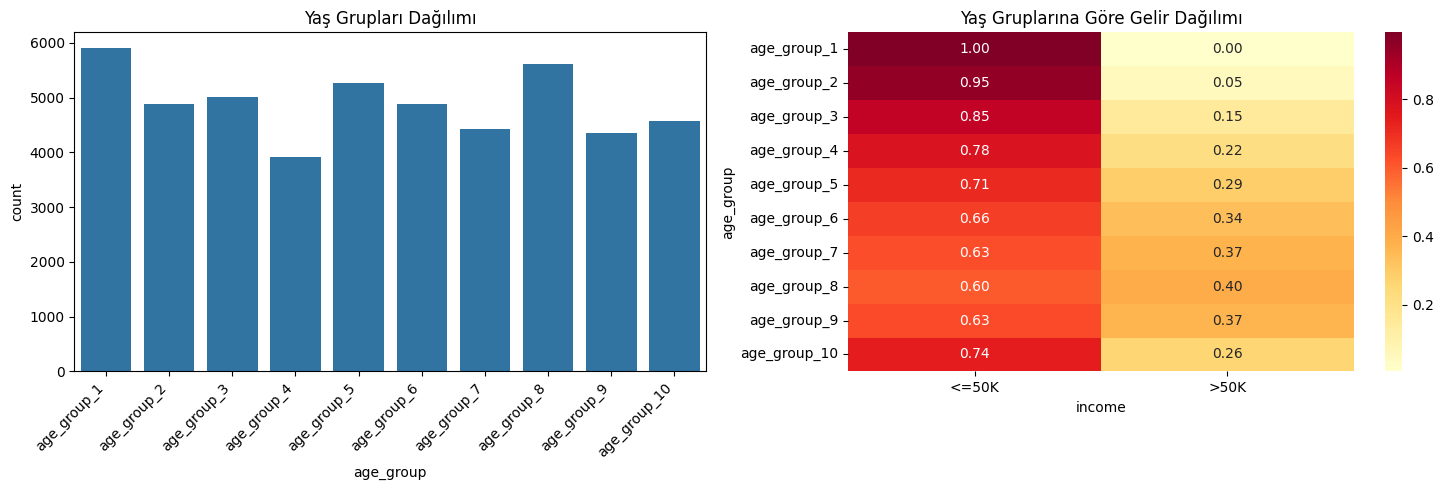

In [52]:
# Altıncı hücre - Yaş grupları analizi
plt.figure(figsize=(15, 5))

# Yaş grupları dağılımı
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='age_group')
plt.title('Yaş Grupları Dağılımı')
plt.xticks(rotation=45, ha='right')

# Yaş gruplarına göre gelir dağılımı
plt.subplot(1, 2, 2)
income_ratio = df.groupby('age_group')['income'].value_counts(normalize=True).unstack()
sns.heatmap(income_ratio, annot=True, fmt='.2f', cmap='YlOrRd')
plt.title('Yaş Gruplarına Göre Gelir Dağılımı')

plt.tight_layout()
plt.show()

# Yaş grupları dağılımı -> Genel olarak gruplar arasında büyük dengesizlikler yok
# Yaş gruplarına göre gelir dağılımı -> Yaş ile gelir arasında belirgin bir ilişki var

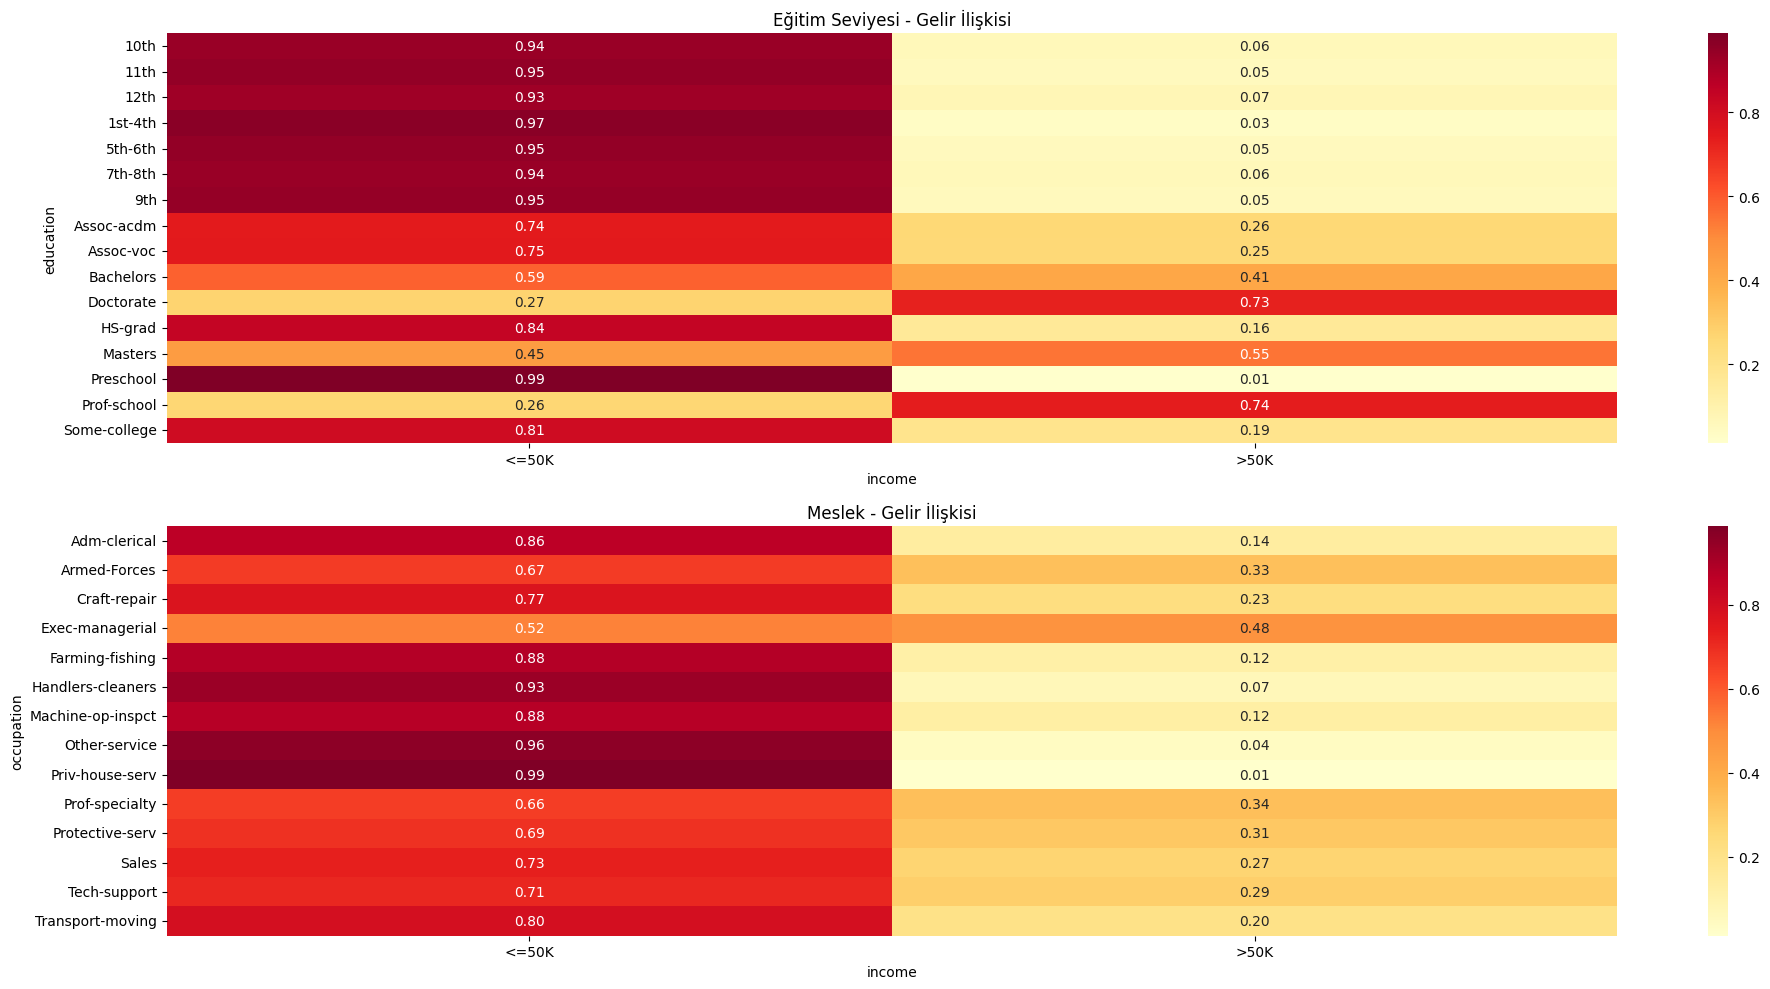

In [53]:
# Eğitim ve meslek analizi
plt.figure(figsize=(20, 10))

# Eğitim seviyesi - Gelir ilişkisi
plt.subplot(2, 1, 1)
education_income = pd.crosstab(df['education'], df['income'], normalize='index')
sns.heatmap(education_income, annot=True, fmt='.2f', cmap='YlOrRd')
plt.title('Eğitim Seviyesi - Gelir İlişkisi')

# Meslek - Gelir ilişkisi
plt.subplot(2, 1, 2)
occupation_income = pd.crosstab(df['occupation'], df['income'], normalize='index')
sns.heatmap(occupation_income, annot=True, fmt='.2f', cmap='YlOrRd')
plt.title('Meslek - Gelir İlişkisi')

plt.tight_layout()
plt.show()


# Eğitim - Gelir İlişkisi -> Eğitim seviyesi arttıkça gelir olasılığı belirgin şekilde artıyor
# Lisansüstü eğitimin yüksek gelir için önemli bir faktör olduğunu gözlemliyoruz

# Meslek - Gelir İlişkisi -> Yönetici ve profesyonel pozisyonlarda yüksek gelir oranı daha fazla
# Hizmet sektörü ve manuel işlerde düşük gelir oranı çok yüksek

# Genel -> Eğitim seviyesi ve meslek, gelir tahmininde çok önemli faktörler
# Bu değişkenler arasındaki güçlü ilişkiler modelde önemli feature'lar olacaktır

# Fairness açısından:
    # Eğitim fırsatlarındaki eşitsizlikler gelir eşitsizliğine yansıyor
    # Meslek grupları arasındaki gelir farklılıkları çok belirgin 


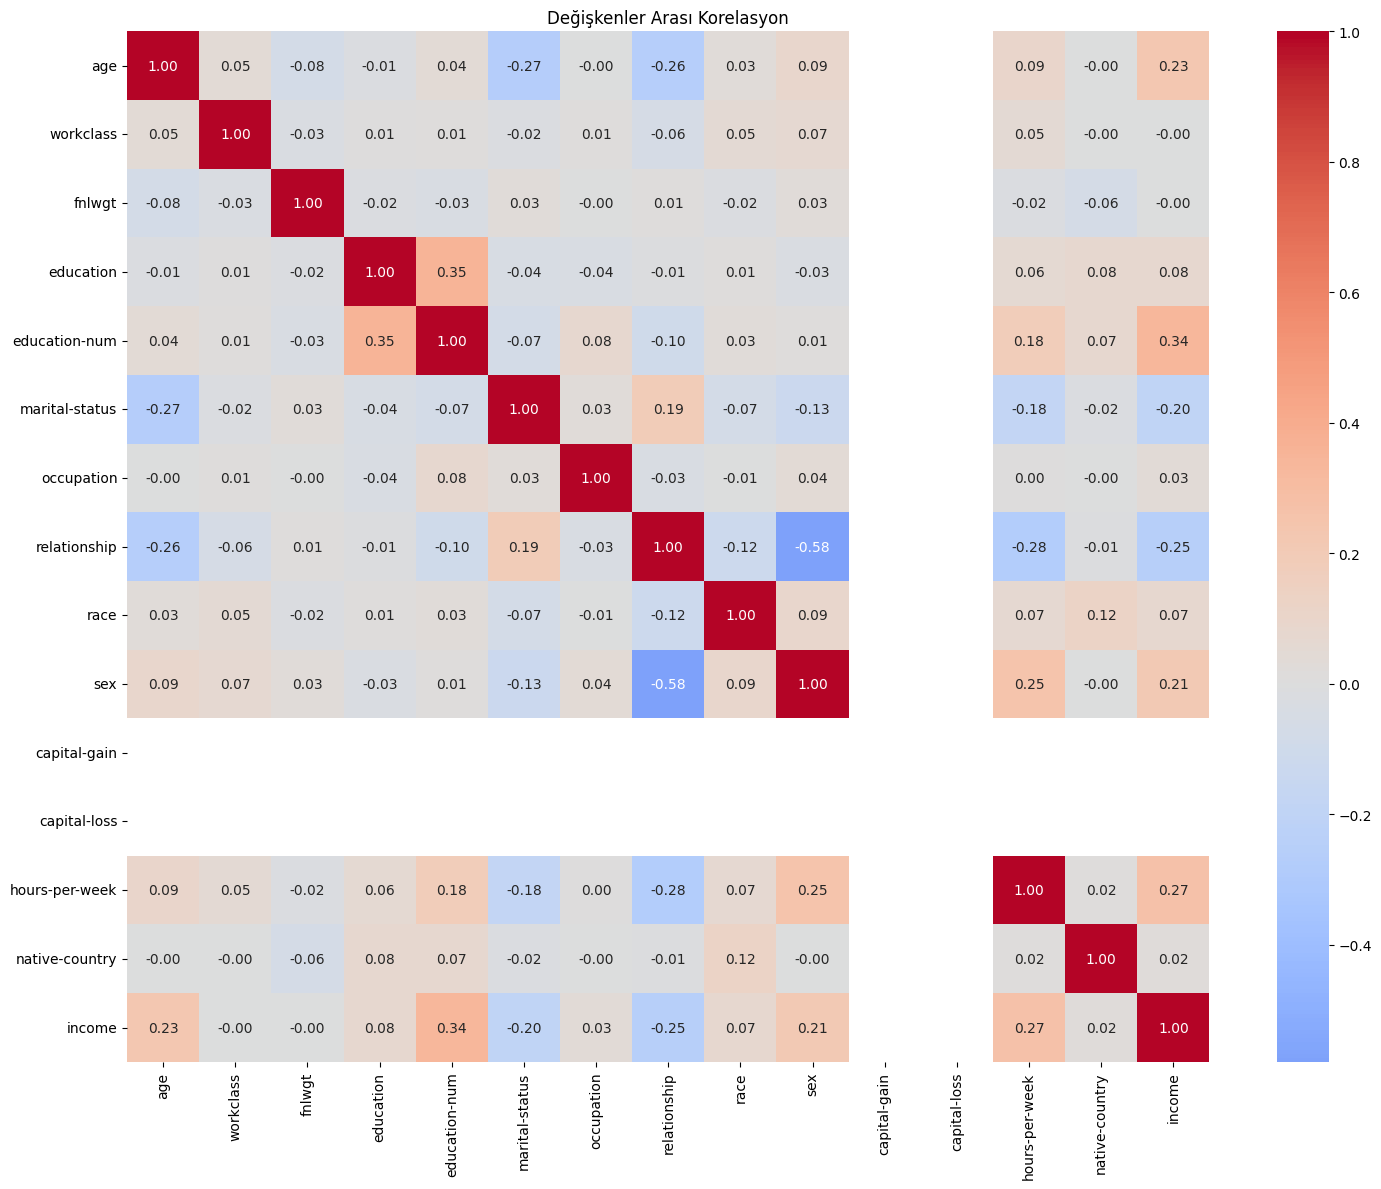


Önemli Korelasyonlar:

age için en yüksek korelasyonlar:
age               1.000000
income            0.231954
hours-per-week    0.093160
Name: age, dtype: float64

workclass için en yüksek korelasyonlar:
workclass    1.000000
sex          0.066672
race         0.053923
Name: workclass, dtype: float64

fnlwgt için en yüksek korelasyonlar:
fnlwgt            1.000000
marital-status    0.030255
sex               0.029547
Name: fnlwgt, dtype: float64

education için en yüksek korelasyonlar:
education        1.000000
education-num    0.352624
income           0.080091
Name: education, dtype: float64

education-num için en yüksek korelasyonlar:
education-num    1.000000
education        0.352624
income           0.339869
Name: education-num, dtype: float64

marital-status için en yüksek korelasyonlar:
marital-status    1.000000
relationship      0.187800
occupation        0.030445
Name: marital-status, dtype: float64

occupation için en yüksek korelasyonlar:
occupation       1.000000
educat

In [54]:
le = LabelEncoder()
df_encoded = df.copy()
df_encoded = df_encoded.drop(['age_group'], axis=1)  # age_group'u çıkar
categorical_columns = df_encoded.select_dtypes(include=['object']).columns
for col in categorical_columns:
    df_encoded[col] = le.fit_transform(df_encoded[col])

# Korelasyon matrisi
plt.figure(figsize=(15, 12))
sns.heatmap(df_encoded.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Değişkenler Arası Korelasyon')
plt.tight_layout()
plt.show()

# Korelasyon değerlerini yazdır
print("\nÖnemli Korelasyonlar:")
corr_matrix = df_encoded.corr()
for col in corr_matrix.columns:
    correlations = corr_matrix[col].sort_values(ascending=False)
    print(f"\n{col} için en yüksek korelasyonlar:")
    print(correlations.head(3))



# Güçlü ilişkiler -> Relationship ve Sex arasında (-0.58), Education ve education-num arasında (0.35)
# Orta ilişkiler -> Education-num ile income (0.34), hours-per-week ile Income(0.27), Age-Income(0.23),
                    # Sex-Income(0.21), Relationship-Income(-0.25)


In [55]:
import pickle
def final_preprocessing(df):
    """Son ön işleme adımlarını gerçekleştirir"""
    # Kategorik değişkenleri kodla
    le = LabelEncoder()
    categorical_columns = df.select_dtypes(include=['object']).columns
    for col in categorical_columns:
        df[col] = le.fit_transform(df[col])
    
    # Özellikler ve hedef değişken
    X = df.drop(['income', 'age_group'], axis=1)
    y = df['income']
    
    # Kategorik özellik indekslerini belirle
    categorical_features = [i for i, col in enumerate(X.columns) 
                          if len(X[col].unique()) < 10]
    
    return X, y, categorical_features, df['age_group']

# Final preprocessing
X, y, categorical_features, age_groups = final_preprocessing(df)

# Veriyi kaydet
preprocessed_data = {
    'X': X,
    'y': y,
    'categorical_features': categorical_features,
    'age_groups': age_groups,
    'feature_names': list(X.columns)
}

with open('preprocessed_data.pkl', 'wb') as f:
    pickle.dump(preprocessed_data, f)

print("\nÖn işleme tamamlandı ve veriler kaydedildi.")
print("Özellik sayısı:", X.shape[1])
print("Kategorik özellik sayısı:", len(categorical_features))
print("Örnek sayısı:", len(y))
print("\nSınıf dağılımı:")
print(pd.Series(y).value_counts(normalize=True))


Ön işleme tamamlandı ve veriler kaydedildi.
Özellik sayısı: 14
Kategorik özellik sayısı: 7
Örnek sayısı: 48842

Sınıf dağılımı:
income
0    0.760718
1    0.239282
Name: proportion, dtype: float64



Özellik önem sıralaması:
                       feature  correlation
education-num    education-num     0.339869
hours-per-week  hours-per-week     0.270255
relationship      relationship     0.253214
age                        age     0.231954
sex                        sex     0.214628
marital-status  marital-status     0.199072
education            education     0.080091
race                      race     0.070934
occupation          occupation     0.032550
native-country  native-country     0.020375
fnlwgt                  fnlwgt     0.004772
workclass            workclass     0.000511
capital-gain      capital-gain          NaN
capital-loss      capital-loss          NaN


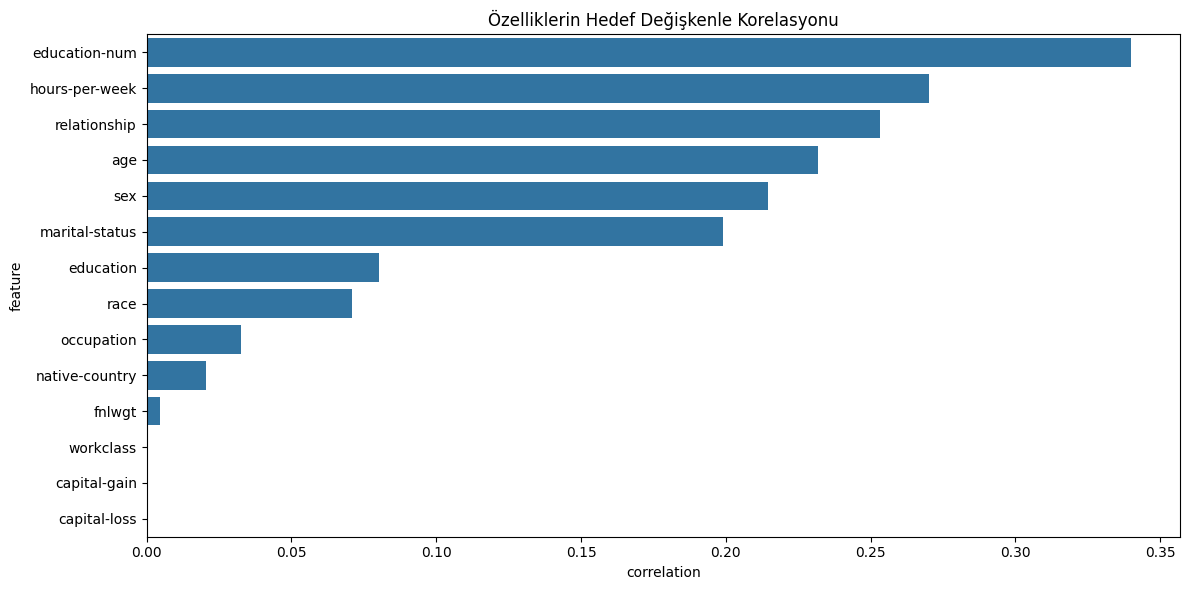

In [56]:
# Onuncu hücre - Özellik önem analizi
print("\nÖzellik önem sıralaması:")
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'correlation': abs(X.corrwith(pd.Series(y)))
}).sort_values('correlation', ascending=False)

print(feature_importance)

plt.figure(figsize=(12, 6))
sns.barplot(data=feature_importance, x='correlation', y='feature')
plt.title('Özelliklerin Hedef Değişkenle Korelasyonu')
plt.tight_layout()
plt.show()